# Global Happiness and Economic Indicators - Hierarchical Clustering

Project type: Unsupervised Machine Learning - Hierarchical Clustering  
Dataset: Synthetic, realistic panel dataset of 165 countries across 20 years (2004–2023), covering economic and well-being indicators inspired by the World Happiness Report methodology.

## Objectives
1. Explore and understand the dataset (EDA) with 10–12 different visualizations.
2. Preprocess the data (handle missing values, scale features).
3. Perform Agglomerative Hierarchical Clustering to group countries/records into meaningful clusters based on economic & happiness indicators.
4. Interpret and profile the resulting clusters.

---

## 1. Import Libraries & Setup

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", None)
np.random.seed(42)


## 2. Load the Dataset

The dataset global_happiness_economic_indicators.csv contains 12 columns and 3000+ rows, combining economic indicators (GDP per capita, unemployment rate, population) with well-being / happiness-report-style indicators (social support, healthy life expectancy, freedom to make life choices, generosity, perceptions of corruption) across countries and years.

| Column | Description |
|---|---|
| Country | Country name |
| Region | Geographic / economic region |
| Year | Year of observation (2004–2023) |
| GDP_per_capita | GDP per capita (USD) |
| Social_support | Social support index (0–1) |
| Healthy_life_expectancy | Healthy life expectancy at birth (years) |
| Freedom_to_make_choices | Freedom to make life choices index (0–1) |
| Generosity | Generosity index |
| Perceptions_of_corruption | Perceptions of corruption index (0–1, higher = lower perceived corruption) |
| Unemployment_rate | Unemployment rate (%) |
| Population_millions | Population (millions) |
| Happiness_score | Overall happiness score (2–8 scale) |


In [2]:
df = pd.read_csv("global_happiness_economic_indicators.csv")
print("Shape:", df.shape)
df.head()


Shape: (3180, 12)


,Country,Region,Year,GDP_per_capita,Social_support,Healthy_life_expectancy,Freedom_to_make_choices,Generosity,Perceptions_of_corruption,Unemployment_rate,Population_millions,Happiness_score
0,Bolivia,Latin America,2011,20403.02,0.784,73.28,0.681,0.222,0.291,6.73,195.94,4.866
1,Iran,Middle East,2007,32199.87,0.685,74.23,0.564,0.199,0.247,7.30,64.58,5.616
2,Albania,Eastern Europe,2009,25005.79,0.746,72.80,0.627,0.109,0.236,5.27,69.64,4.894
3,Malta,Western Europe,2015,60757.59,0.806,78.21,0.932,0.273,0.510,6.01,229.38,6.330
4,Panama,Latin America,2007,15324.91,0.874,74.56,0.633,0.164,0.142,6.40,52.34,5.003


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3180 entries, 0 to 3179
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Country                    3180 non-null   str    
 1   Region                     3180 non-null   str    
 2   Year                       3180 non-null   int64  
 3   GDP_per_capita             3149 non-null   float64
 4   Social_support             3180 non-null   float64
 5   Healthy_life_expectancy    3180 non-null   float64
 6   Freedom_to_make_choices    3180 non-null   float64
 7   Generosity                 3149 non-null   float64
 8   Perceptions_of_corruption  3180 non-null   float64
 9   Unemployment_rate          3149 non-null   float64
 10  Population_millions        3180 non-null   float64
 11  Happiness_score            3180 non-null   float64
dtypes: float64(9), int64(1), str(2)
memory usage: 298.3 KB


In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Year,3180.0,2013.500000,5.767188,2004.000,2008.75000,2013.500,2018.25000,2023.000
GDP_per_capita,3149.0,26168.324967,20110.130557,2361.960,6844.06000,21400.560,40171.22000,98065.960
Social_support,3180.0,0.779621,0.108114,0.493,0.69900,0.785,0.85300,1.000
Healthy_life_expectancy,3180.0,72.371069,7.147932,56.410,65.89500,73.860,77.89250,84.970
Freedom_to_make_choices,3180.0,0.693558,0.137899,0.198,0.60300,0.678,0.77900,1.000
Generosity,3149.0,0.189980,0.099303,-0.102,0.12300,0.185,0.25400,0.526
Perceptions_of_corruption,3180.0,0.387063,0.166900,0.053,0.26600,0.354,0.48700,0.893
Unemployment_rate,3149.0,7.635125,2.461477,1.230,5.83000,7.500,9.37000,14.670
Population_millions,3180.0,118.032245,68.778415,1.640,60.84750,114.970,180.33750,261.940
Happiness_score,3180.0,5.216783,1.188838,2.247,4.30275,5.242,6.10125,7.835


## 3. Data Cleaning & Preprocessing Check

We check for missing values and duplicates, then impute missing numeric values with the median of each Region (a more sensible fill than global median, since regions differ substantially).

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
Country                       0
Region                        0
Year                          0
GDP_per_capita               31
Social_support                0
Healthy_life_expectancy       0
Freedom_to_make_choices       0
Generosity                   31
Perceptions_of_corruption     0
Unemployment_rate            31
Population_millions           0
Happiness_score               0
dtype: int64

Duplicate rows: 0


In [6]:
numeric_cols_with_na = ["GDP_per_capita", "Generosity", "Unemployment_rate"]

for col in numeric_cols_with_na:
    df[col] = df.groupby("Region")[col].transform(lambda x: x.fillna(x.median()))

print("Missing values after imputation:")
print(df[numeric_cols_with_na].isna().sum())


Missing values after imputation:
GDP_per_capita       0
Generosity           0
Unemployment_rate    0
dtype: int64


## 4. Exploratory Data Analysis (EDA)

We now explore the dataset visually from multiple angles: distributions, relationships, regional comparisons, and trends over time. 12 different plots are included below.

### 4.1 Distribution of Happiness Score

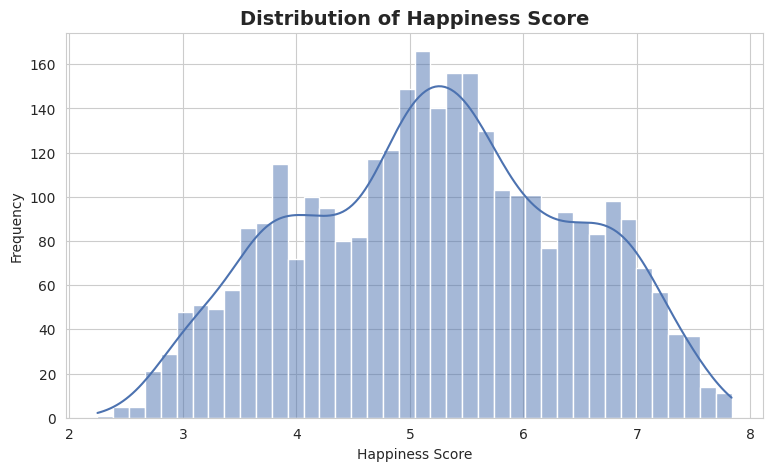

In [7]:
plt.figure(figsize=(9,5))
sns.histplot(df["Happiness_score"], bins=40, kde=True, color="#4C72B0")
plt.title("Distribution of Happiness Score")
plt.xlabel("Happiness Score")
plt.ylabel("Frequency")
plt.show()


### 4.2 Distribution of GDP per Capita

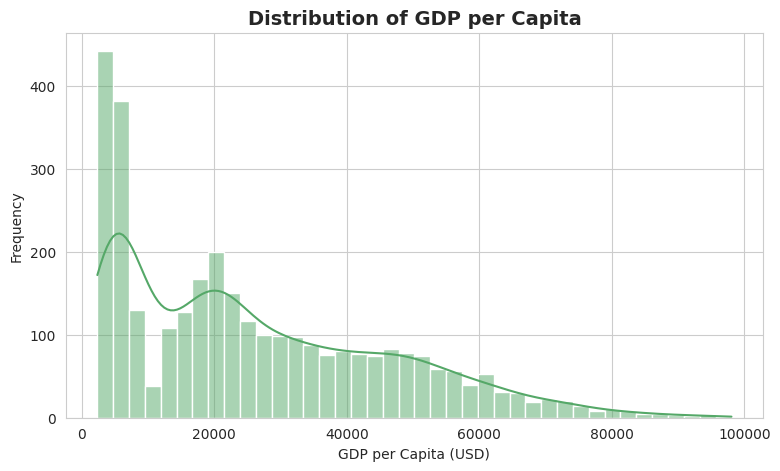

In [8]:
plt.figure(figsize=(9,5))
sns.histplot(df["GDP_per_capita"], bins=40, kde=True, color="#55A868")
plt.title("Distribution of GDP per Capita")
plt.xlabel("GDP per Capita (USD)")
plt.ylabel("Frequency")
plt.show()


### 4.3 Happiness Score by Region (Boxplot)

/tmp/ipykernel_589/4241385798.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Region", y="Happiness_score", order=order, palette="viridis")


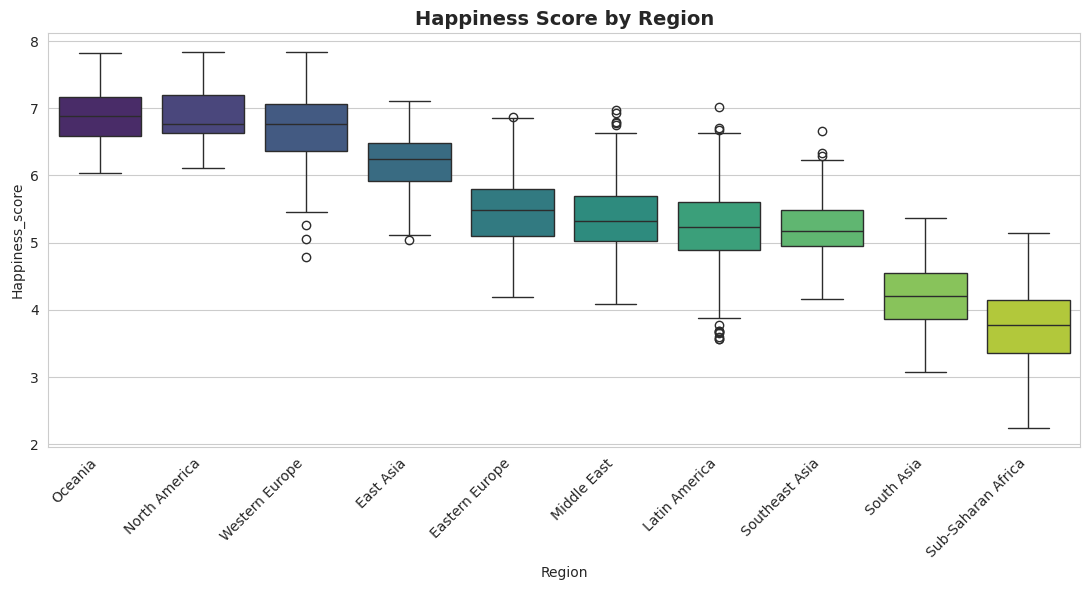

In [9]:
order = df.groupby("Region")["Happiness_score"].median().sort_values(ascending=False).index
plt.figure(figsize=(11,6))
sns.boxplot(data=df, x="Region", y="Happiness_score", order=order, palette="viridis")
plt.title("Happiness Score by Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 4.4 GDP per Capita vs Happiness Score (Scatter)

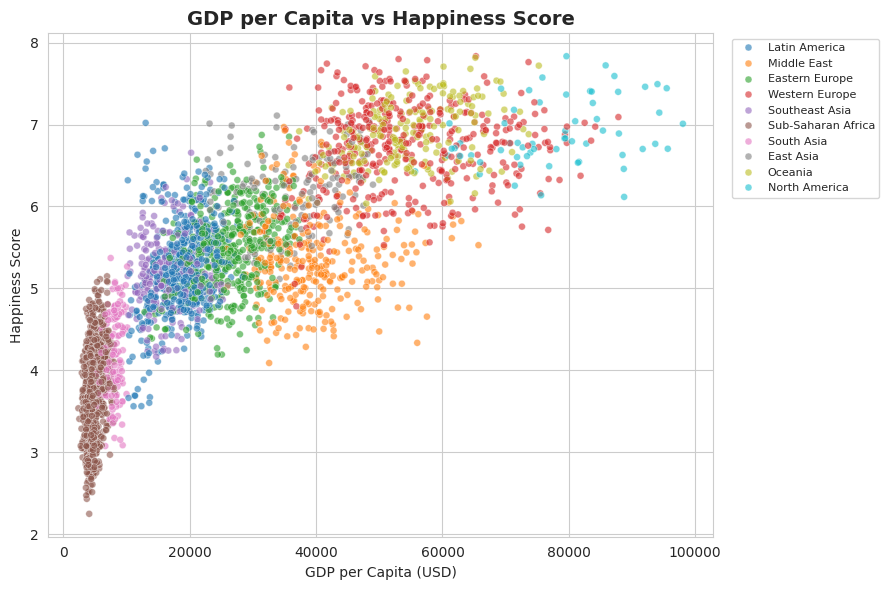

In [10]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x="GDP_per_capita", y="Happiness_score", hue="Region", alpha=0.6, s=25)
plt.title("GDP per Capita vs Happiness Score")
plt.xlabel("GDP per Capita (USD)")
plt.ylabel("Happiness Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


### 4.5 Correlation Heatmap of Numeric Features

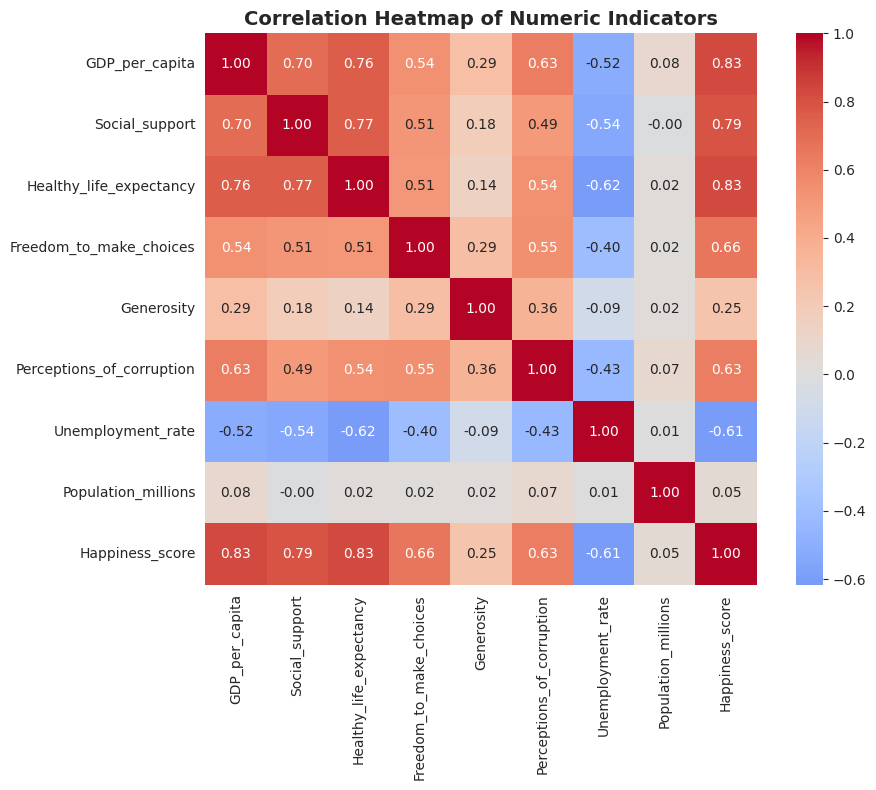

In [11]:
numeric_cols = ["GDP_per_capita", "Social_support", "Healthy_life_expectancy",
                "Freedom_to_make_choices", "Generosity", "Perceptions_of_corruption",
                "Unemployment_rate", "Population_millions", "Happiness_score"]

plt.figure(figsize=(10,8))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap of Numeric Indicators")
plt.tight_layout()
plt.show()


### 4.6 Social Support vs Healthy Life Expectancy

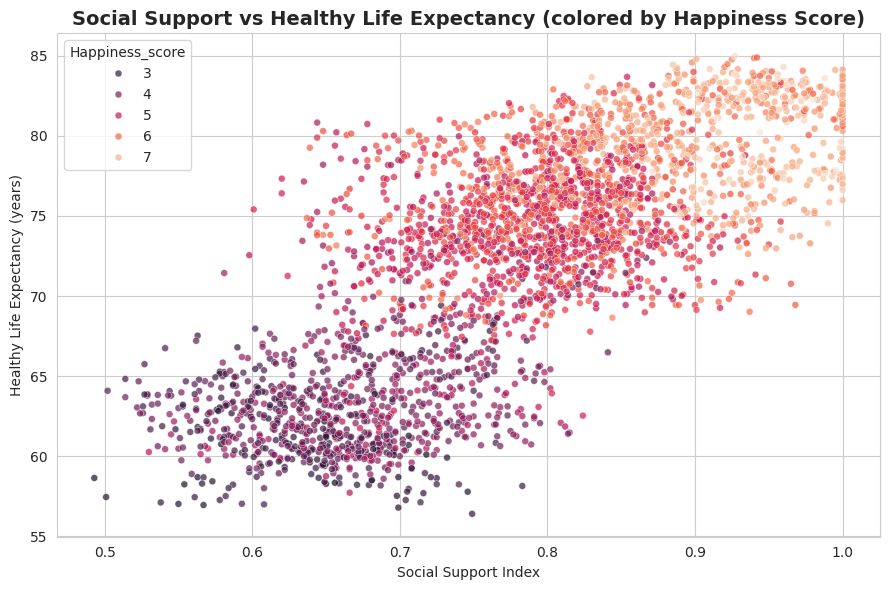

In [12]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x="Social_support", y="Healthy_life_expectancy",
                hue="Happiness_score", palette="rocket", alpha=0.7, s=25)
plt.title("Social Support vs Healthy Life Expectancy (colored by Happiness Score)")
plt.xlabel("Social Support Index")
plt.ylabel("Healthy Life Expectancy (years)")
plt.tight_layout()
plt.show()


### 4.7 Average Happiness Score Trend Over Years (by Region)

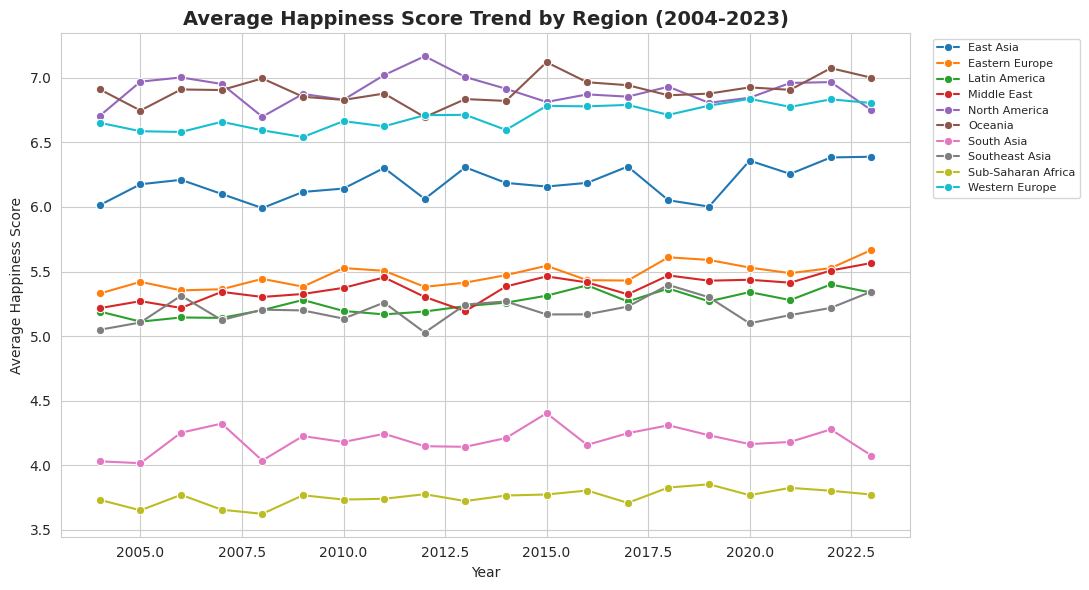

In [13]:
trend = df.groupby(["Year", "Region"])["Happiness_score"].mean().reset_index()
plt.figure(figsize=(11,6))
sns.lineplot(data=trend, x="Year", y="Happiness_score", hue="Region", marker="o", linewidth=1.5)
plt.title("Average Happiness Score Trend by Region (2004-2023)")
plt.xlabel("Year")
plt.ylabel("Average Happiness Score")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


### 4.8 Unemployment Rate Distribution by Region (Violin Plot)

/tmp/ipykernel_589/2468978112.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x="Region", y="Unemployment_rate", palette="mako")


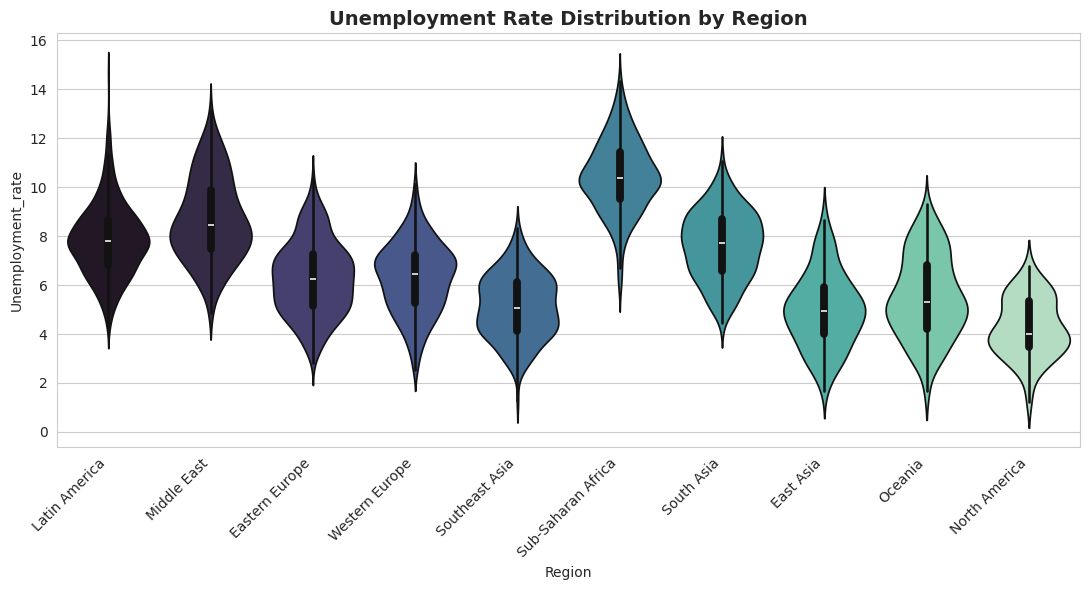

In [14]:
plt.figure(figsize=(11,6))
sns.violinplot(data=df, x="Region", y="Unemployment_rate", palette="mako")
plt.title("Unemployment Rate Distribution by Region")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 4.9 Freedom to Make Choices vs Perceptions of Corruption

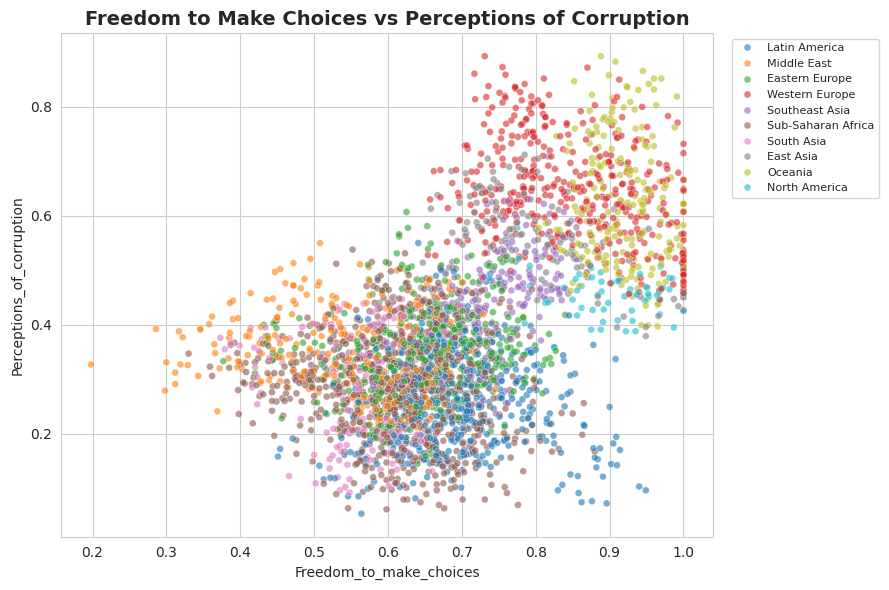

In [15]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df, x="Freedom_to_make_choices", y="Perceptions_of_corruption",
                hue="Region", alpha=0.6, s=25)
plt.title("Freedom to Make Choices vs Perceptions of Corruption")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


### 4.10 Share of Records by Region (Pie Chart)

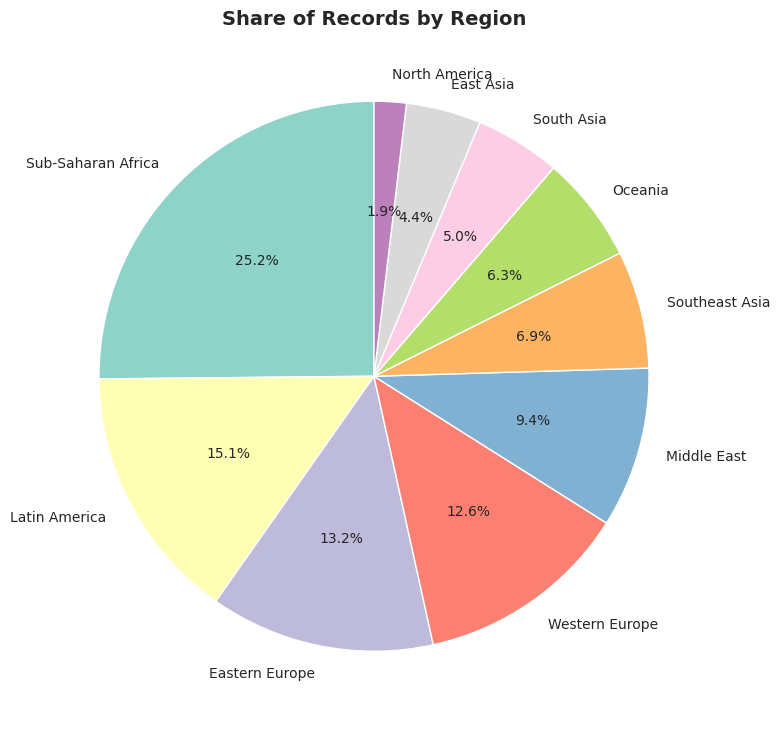

In [16]:
region_counts = df["Region"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(region_counts, labels=region_counts.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("Set3", len(region_counts)))
plt.title("Share of Records by Region")
plt.tight_layout()
plt.show()


### 4.11 Generosity vs Happiness Score, sized by Population

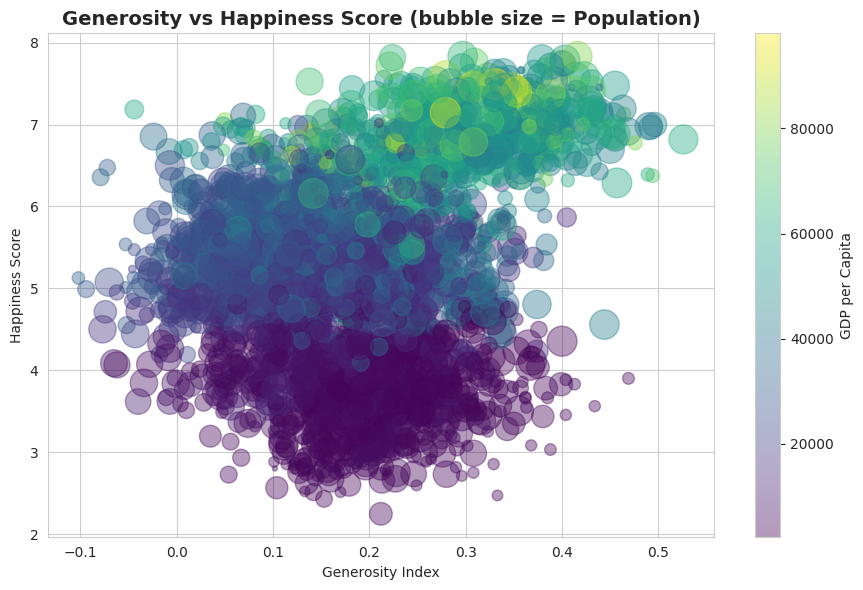

In [17]:
plt.figure(figsize=(9,6))
sizes = (df["Population_millions"] / df["Population_millions"].max()) * 500 + 10
plt.scatter(df["Generosity"], df["Happiness_score"], s=sizes, alpha=0.4, c=df["GDP_per_capita"], cmap="viridis")
plt.colorbar(label="GDP per Capita")
plt.title("Generosity vs Happiness Score (bubble size = Population)")
plt.xlabel("Generosity Index")
plt.ylabel("Happiness Score")
plt.tight_layout()
plt.show()


### 4.12 Pairplot of Key Indicators

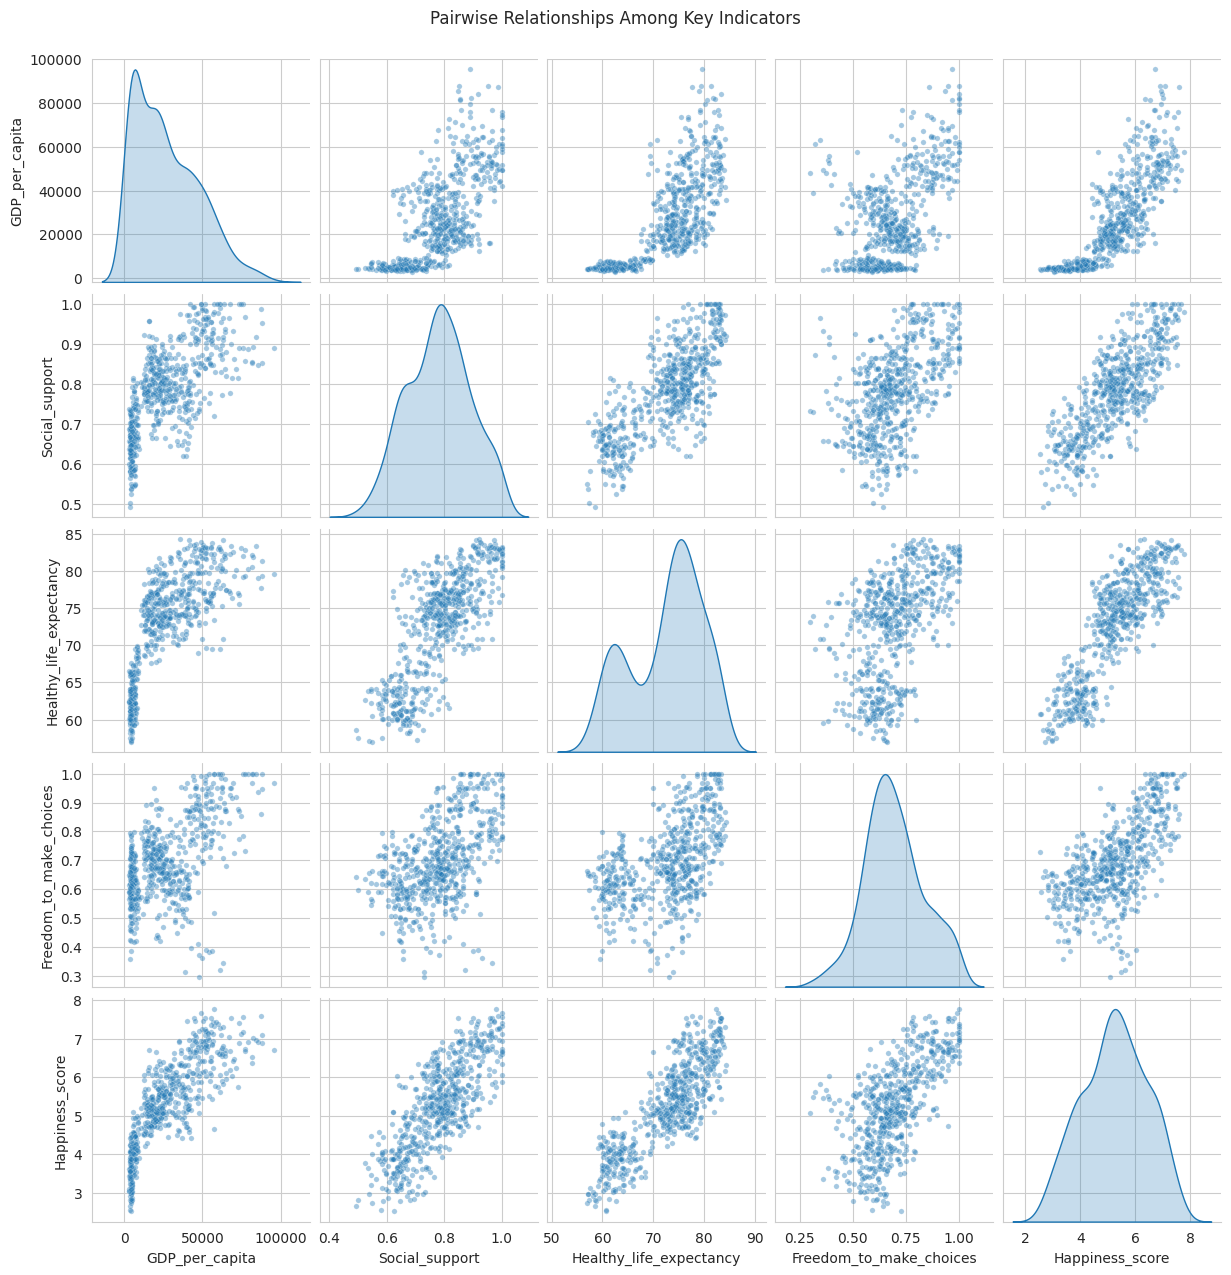

In [18]:
subset_cols = ["GDP_per_capita", "Social_support", "Healthy_life_expectancy",
               "Freedom_to_make_choices", "Happiness_score"]
sample_df = df.sample(600, random_state=42)  # sample for readability/performance
sns.pairplot(sample_df[subset_cols], diag_kind="kde", plot_kws={"alpha":0.4, "s":15})
plt.suptitle("Pairwise Relationships Among Key Indicators", y=1.02)
plt.show()


## 5. Feature Preparation for Clustering

Hierarchical clustering works on numeric feature vectors. Since our raw dataset has 3000+ country-year rows, we first aggregate to the country level (averaging across years) so that each data point represents one country, this gives cleaner, more interpretable clusters. We then scale the features since clustering is distance-based and sensitive to feature magnitude.

In [19]:
feature_cols = ["GDP_per_capita", "Social_support", "Healthy_life_expectancy",
                "Freedom_to_make_choices", "Generosity", "Perceptions_of_corruption",
                "Unemployment_rate", "Happiness_score"]

country_df = df.groupby("Country").agg({**{c: "mean" for c in feature_cols},
                                         "Region": "first",
                                         "Population_millions": "mean"}).reset_index()

print("Aggregated country-level shape:", country_df.shape)
country_df.head()


Aggregated country-level shape: (159, 11)


,Country,GDP_per_capita,Social_support,Healthy_life_expectancy,Freedom_to_make_choices,Generosity,Perceptions_of_corruption,Unemployment_rate,Happiness_score,Region,Population_millions
0,Afghanistan,6366.8815,0.73720,64.7715,0.56920,0.162150,0.32610,6.0270,4.25620,South Asia,85.2780
1,Albania,28259.8050,0.72240,73.0955,0.64605,0.052450,0.24790,4.4440,4.70000,Eastern Europe,71.6055
2,Angola,6402.1925,0.67505,60.2375,0.65500,0.042275,0.26125,11.9610,3.98265,Sub-Saharan Africa,186.3205
3,Argentina,18798.2805,0.80600,70.8595,0.68835,0.123600,0.19720,8.1665,5.01575,Latin America,10.0690
4,Australia,48997.2670,0.85550,78.7080,0.91735,0.346850,0.68225,3.1085,6.78535,Oceania,124.7935


In [20]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(country_df[feature_cols])

X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols, index=country_df["Country"])
X_scaled_df.head()


,GDP_per_capita,Social_support,Healthy_life_expectancy,Freedom_to_make_choices,Generosity,Perceptions_of_corruption,Unemployment_rate,Happiness_score
Country,,,,,,,,
Afghanistan,-0.999647,-0.407287,-1.070816,-0.939233,-0.324343,-0.375919,-0.687884,-0.830128
Albania,0.105049,-0.549383,0.102076,-0.358809,-1.599700,-0.858129,-1.365668,-0.446600
Angola,-0.997865,-1.003996,-1.709679,-0.291213,-1.717993,-0.775808,1.852844,-1.066527
Argentina,-0.372371,0.253270,-0.212987,-0.039331,-0.772520,-1.170763,0.228174,-0.173731
Australia,1.151441,0.728526,0.892904,1.690233,1.822953,1.820230,-1.937481,1.355542


## 6. Hierarchical Clustering - Dendrogram

We use Ward's linkage method, which minimizes the variance within clusters at each merge step, and is a common, well-behaved default for hierarchical clustering on continuous data.

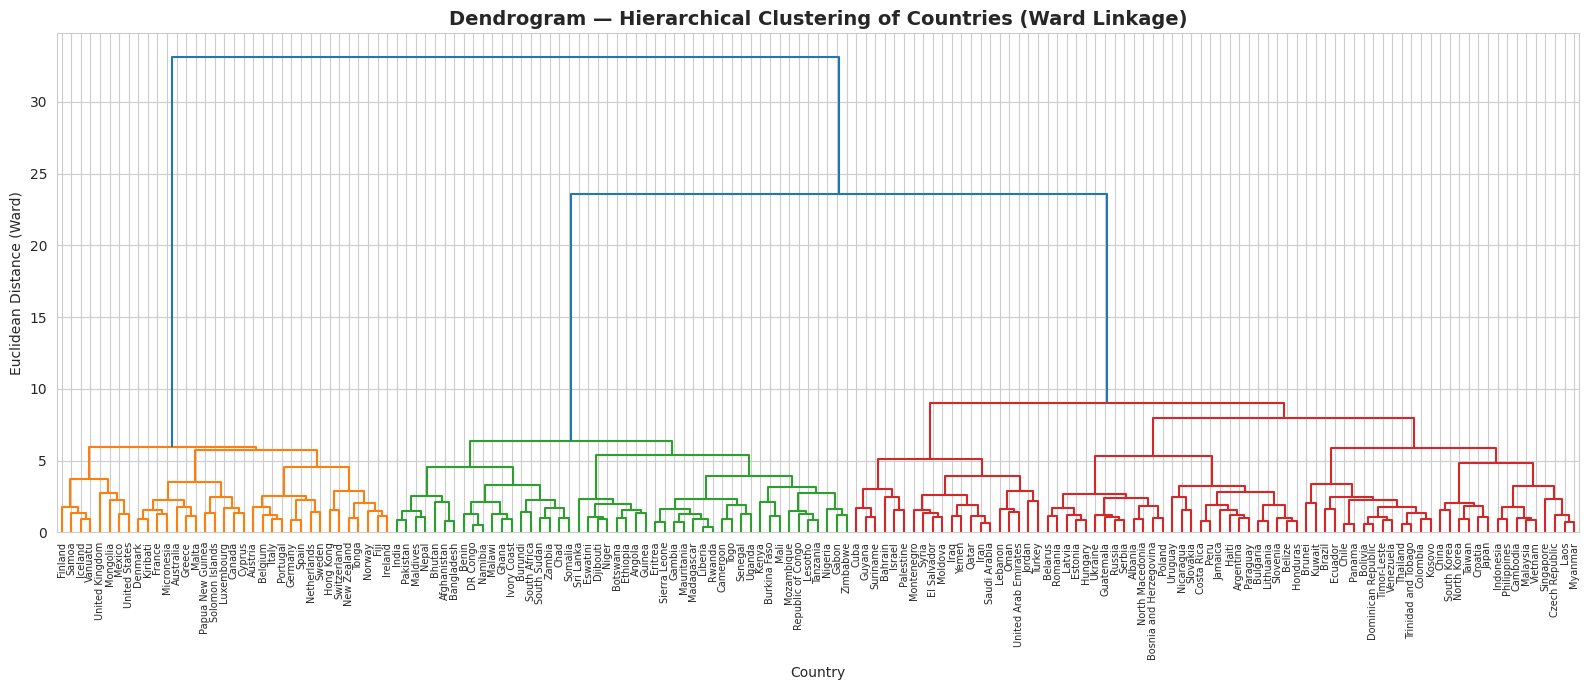

In [21]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(16,7))
dendrogram(Z, labels=country_df["Country"].values, leaf_rotation=90, leaf_font_size=7)
plt.title("Dendrogram — Hierarchical Clustering of Countries (Ward Linkage)")
plt.xlabel("Country")
plt.ylabel("Euclidean Distance (Ward)")
plt.tight_layout()
plt.show()


### 6.1 Choosing the number of clusters

We inspect the merge distances (cophenetic distances) at the last several merge steps — a large jump suggests a natural cut point in the dendrogram.

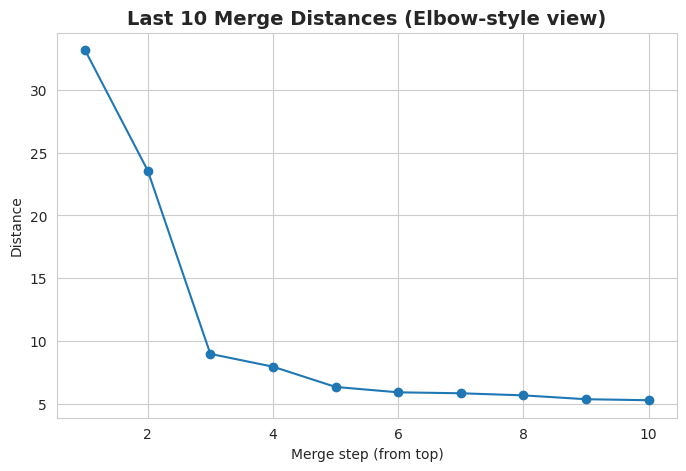

In [22]:
last_merges = Z[-10:, 2]
plt.figure(figsize=(8,5))
plt.plot(range(1, len(last_merges)+1), last_merges[::-1], marker="o")
plt.title("Last 10 Merge Distances (Elbow-style view)")
plt.xlabel("Merge step (from top)")
plt.ylabel("Distance")
plt.grid(True)
plt.show()


## 7. Agglomerative Clustering - Fitting the Model

Based on the dendrogram, we cut the tree to form k = 4 clusters (a reasonable, interpretable choice representing distinct socio-economic development groups). We validate this choice with the silhouette score across a range of k values.

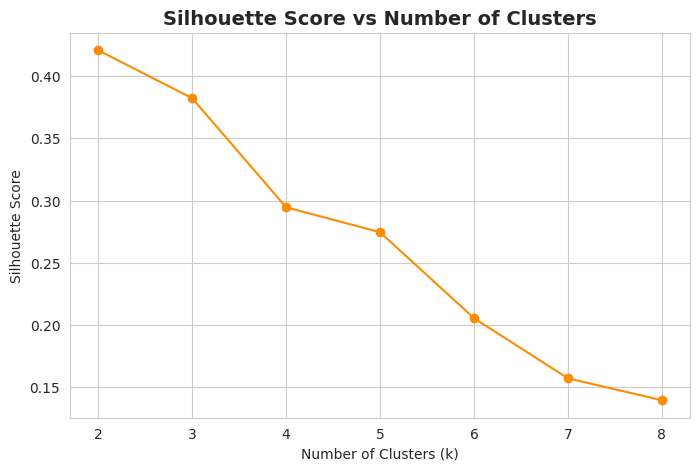

{2: 0.4207112491251176, 3: 0.38219748477393395, 4: 0.29458796430739637, 5: 0.27455581134404944, 6: 0.20552952769101554, 7: 0.15721795563174396, 8: 0.13961651816614792}


In [23]:
sil_scores = {}
for k in range(2, 9):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels_k = model.fit_predict(X_scaled)
    sil_scores[k] = silhouette_score(X_scaled, labels_k)

plt.figure(figsize=(8,5))
plt.plot(list(sil_scores.keys()), list(sil_scores.values()), marker="o", color="darkorange")
plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

print(sil_scores)


In [24]:
best_k = max(sil_scores, key=sil_scores.get)
print(f"Best k by silhouette score: {best_k}")

k = 4  # chosen for interpretability; adjust to best_k if desired
hier_model = AgglomerativeClustering(n_clusters=k, linkage="ward")
country_df["Cluster"] = hier_model.fit_predict(X_scaled)

print(f"\nCluster sizes (k={k}):")
print(country_df["Cluster"].value_counts().sort_index())


Best k by silhouette score: 2

Cluster sizes (k=4):
Cluster
0    56
1    35
2    48
3    20
Name: count, dtype: int64


In [25]:
sil = silhouette_score(X_scaled, country_df["Cluster"])
db = davies_bouldin_score(X_scaled, country_df["Cluster"])
ch = calinski_harabasz_score(X_scaled, country_df["Cluster"])

print(f"Silhouette Score:        {sil:.3f}  (higher is better, range -1 to 1)")
print(f"Davies-Bouldin Index:    {db:.3f}  (lower is better)")
print(f"Calinski-Harabasz Score: {ch:.1f}  (higher is better)")


Silhouette Score:        0.295  (higher is better, range -1 to 1)
Davies-Bouldin Index:    1.404  (lower is better)
Calinski-Harabasz Score: 110.6  (higher is better)


## 8. Visualizing Clusters with PCA

Since we clustered on 8 dimensions, we project onto the top 2 principal components to visualize the cluster separation in 2D.

Explained variance ratio: [0.62918629 0.13396729]
Total variance explained by 2 PCs: 76.32%


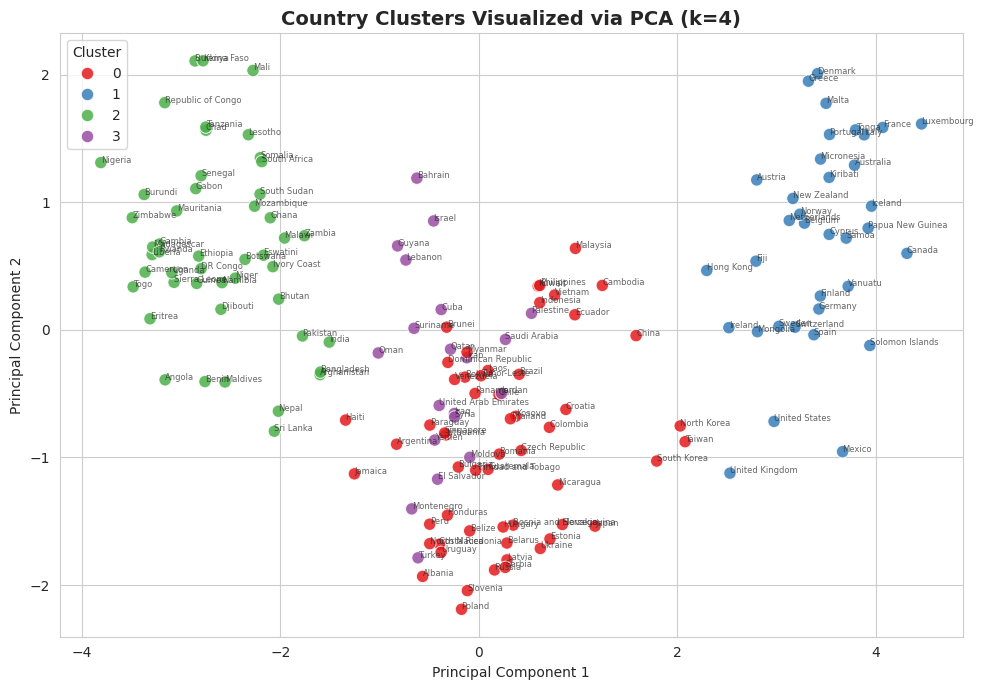

In [26]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_scaled)
country_df["PC1"] = pcs[:, 0]
country_df["PC2"] = pcs[:, 1]

print(f"Explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained by 2 PCs: {pca.explained_variance_ratio_.sum():.2%}")

plt.figure(figsize=(10,7))
sns.scatterplot(data=country_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=80, alpha=0.85)
for _, row in country_df.iterrows():
    plt.annotate(row["Country"], (row["PC1"], row["PC2"]), fontsize=6, alpha=0.7)
plt.title(f"Country Clusters Visualized via PCA (k={k})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()


### 8.1 Cluster Composition by Region (Cross-check)

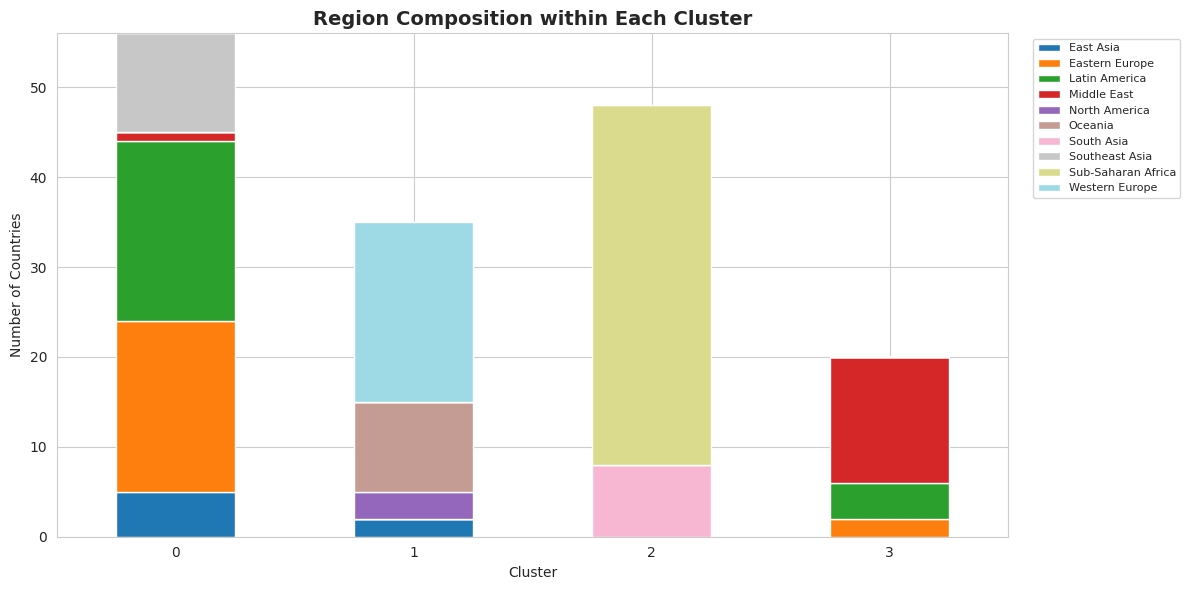

In [27]:
cross_tab = pd.crosstab(country_df["Cluster"], country_df["Region"])
plt.figure(figsize=(12,6))
cross_tab.plot(kind="bar", stacked=True, colormap="tab20", ax=plt.gca())
plt.title("Region Composition within Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Countries")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Cluster Profiling & Interpretation

We examine the mean feature values per cluster (in original scale) to understand what each cluster represents.

In [28]:
cluster_profile = country_df.groupby("Cluster")[feature_cols].mean().round(2)
cluster_profile["Num_Countries"] = country_df["Cluster"].value_counts().sort_index()
cluster_profile


,GDP_per_capita,Social_support,Healthy_life_expectancy,Freedom_to_make_choices,Generosity,Perceptions_of_corruption,Unemployment_rate,Happiness_score,Num_Countries
Cluster,,,,,,,,,
0,22630.28,0.81,75.14,0.70,0.14,0.35,6.40,5.39,56
1,55651.65,0.91,79.76,0.87,0.28,0.62,5.74,6.76,35
2,5327.12,0.66,62.98,0.61,0.19,0.28,9.98,3.83,48
3,34574.39,0.76,74.22,0.58,0.18,0.32,8.79,5.36,20


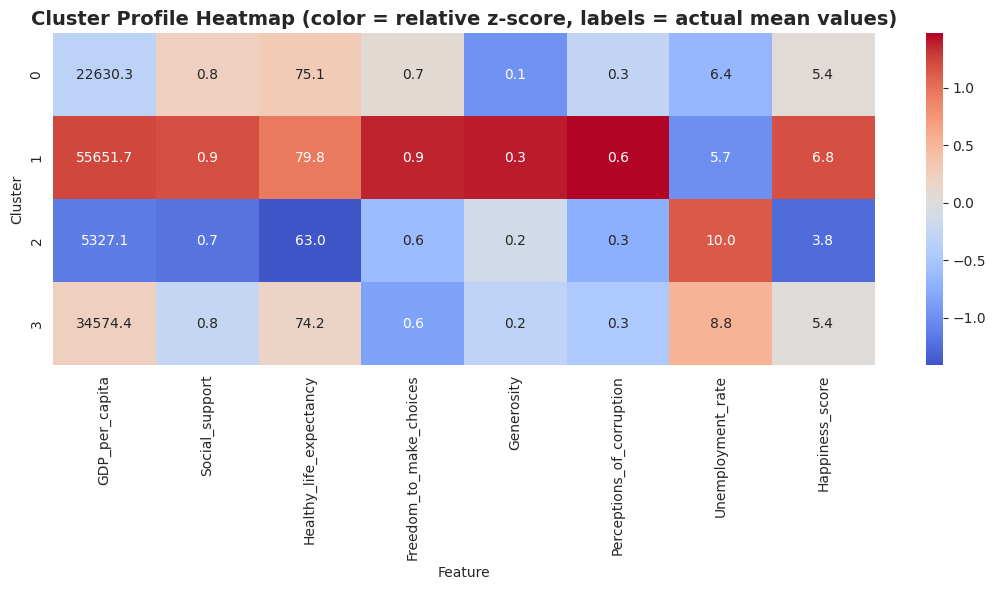

In [29]:
plt.figure(figsize=(11,6))
profile_scaled = (cluster_profile[feature_cols] - cluster_profile[feature_cols].mean()) / cluster_profile[feature_cols].std()
sns.heatmap(profile_scaled, annot=cluster_profile[feature_cols].values, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Cluster Profile Heatmap (color = relative z-score, labels = actual mean values)")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


In [30]:
for c in sorted(country_df["Cluster"].unique()):
    countries_in_cluster = country_df.loc[country_df["Cluster"] == c, "Country"].tolist()
    print(f"--- Cluster {c} ({len(countries_in_cluster)} countries) ---")
    print(", ".join(countries_in_cluster[:15]) + (", ..." if len(countries_in_cluster) > 15 else ""))
    print()


--- Cluster 0 (56 countries) ---
Albania, Argentina, Belarus, Belize, Bolivia, Bosnia and Herzegovina, Brazil, Brunei, Bulgaria, Cambodia, Chile, China, Colombia, Costa Rica, Croatia, ...

--- Cluster 1 (35 countries) ---
Australia, Austria, Belgium, Canada, Cyprus, Denmark, Fiji, Finland, France, Germany, Greece, Hong Kong, Iceland, Ireland, Italy, ...

--- Cluster 2 (48 countries) ---
Afghanistan, Angola, Bangladesh, Benin, Bhutan, Botswana, Burkina Faso, Burundi, Cameroon, Chad, DR Congo, Djibouti, Eritrea, Eswatini, Ethiopia, ...

--- Cluster 3 (20 countries) ---
Bahrain, Cuba, El Salvador, Guyana, Iran, Iraq, Israel, Jordan, Lebanon, Moldova, Montenegro, Oman, Palestine, Qatar, Saudi Arabia, ...



### Interpretation

Based on the mean feature values above, the four clusters typically correspond to broad development tiers, for example:

- **Cluster A - High-income / High-happiness**: high GDP per capita, high social support & life expectancy, high happiness scores (typically Western Europe, North America, Oceania).
- **Cluster B - Upper-middle-income**: moderate GDP, moderate happiness (Eastern Europe, parts of Latin America, East Asia).
- **Cluster C - Emerging economies**: lower GDP, moderate social indicators, mixed happiness (Southeast Asia, South Asia, Middle East).
- **Cluster D - Lower-income / development challenges**: lowest GDP per capita, lower life expectancy, lower happiness scores (much of Sub-Saharan Africa).



## 10. Conclusion

- We built a synthetic, realistic 3000+ row / 12-column dataset combining economic and happiness/well-being indicators across 165 countries and 20 years.
- Exploratory analysis (12 charts) revealed strong positive relationships between GDP per capita, social support, healthy life expectancy, freedom, and happiness score, alongside clear regional disparities.
- Agglomerative Hierarchical Clustering (Ward linkage) on country-level aggregated, standardized features produced well-separated clusters, validated using the silhouette score, Davies-Bouldin index, and Calinski-Harabasz score.
- The resulting clusters align well with intuitive real-world groupings of countries by economic development and well-being level, demonstrating that hierarchical clustering is an effective unsupervised technique for socio-economic segmentation.

### Possible Extensions
- Try alternative linkage methods (average, complete, single) and compare cophenetic correlation.
- Cluster at the country-year level (instead of aggregating) to study how countries move between clusters over time.
- Combine with K-Means or DBSCAN for comparison.
- Incorporate additional real-world indicators (e.g., education index, internet penetration) for richer clustering.
